## Kiedy filtry widmowe?

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import time
from skimage import data, color, restoration
from scipy.fft import fft2, fftshift, ifft2, ifftshift
from scipy.signal import convolve2d, fftconvolve

def show_images(images, titles, figsize=(15, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    if len(images) == 1: axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap='gray')
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 1. Wydajność obliczeniowa.

Dla bardzo dużych filtrów (np. rozmycie o promieniu kilkudziesięciu pikseli) tradycyjny splot matematyczny na poziomie pikseli jest niezwykle wolny, bo jego złożoność rośnie kwadratowo.
Zgodnie z *Twierdzeniem o splocie*, splot w dziedzinie przestrzeni to po prostu mnożenie w dziedzinie częstotliwości. Użycie Szybkiej Transformaty Fouriera (FFT) pozwala ominąć ten problem i drastycznie przyspieszyć obliczenia.

In [19]:
img_astro = color.rgb2gray(data.astronaut())

# Tworzymy ogromny filtr uśredniający: macierz 75x75 pikseli
kernel_size = 75
kernel = np.ones((kernel_size, kernel_size)) / (kernel_size**2)

# 1. Zwykły splot przestrzenny (przesuwanie okna nad obrazem)
start = time.time()
res_spatial = convolve2d(img_astro, kernel, mode='same')
time_spatial = time.time() - start

# 2. Splot widmowy za pomocą FFT (transformata, mnożenie, odwrotna transformata)
start = time.time()
res_fft = fftconvolve(img_astro, kernel, mode='same')
time_fft = time.time() - start

print(f"Czas tradycyjnego splotu przestrzennego: {time_spatial:.4f} s")
print(f"Czas splotu widmowego (FFT):             {time_fft:.4f} s")
print(f"\nWniosek: Dla dużych filtrów analiza widmowa jest ~{time_spatial/time_fft:.1f} razy szybsza!")

# Opcjonalnie: wyświetlenie wyniku (są identyczne)
# show_images([img_astro, res_fft], ['Oryginał', 'Rozmycie Gigantycznym Filtrem (FFT)'])

Czas tradycyjnego splotu przestrzennego: 3.0850 s
Czas splotu widmowego (FFT):             0.0105 s

Wniosek: Dla dużych filtrów analiza widmowa jest ~294.7 razy szybsza!


### 2. Usuwanie szumów okresowych 

Zwykły splot widzi tylko to, co pod małym oknem – nie "zauważa" globalnych, regularnych wzorów (mora z prasy drukarskiej, zakłócenia sprzętowe z pola magnetycznego itp.). 

W widmie Fouriera takie zakłócenia zbijają się w jasne kropki, co pozwala na ich "chirurgiczne" wycięcie bez psucia reszty obrazu.

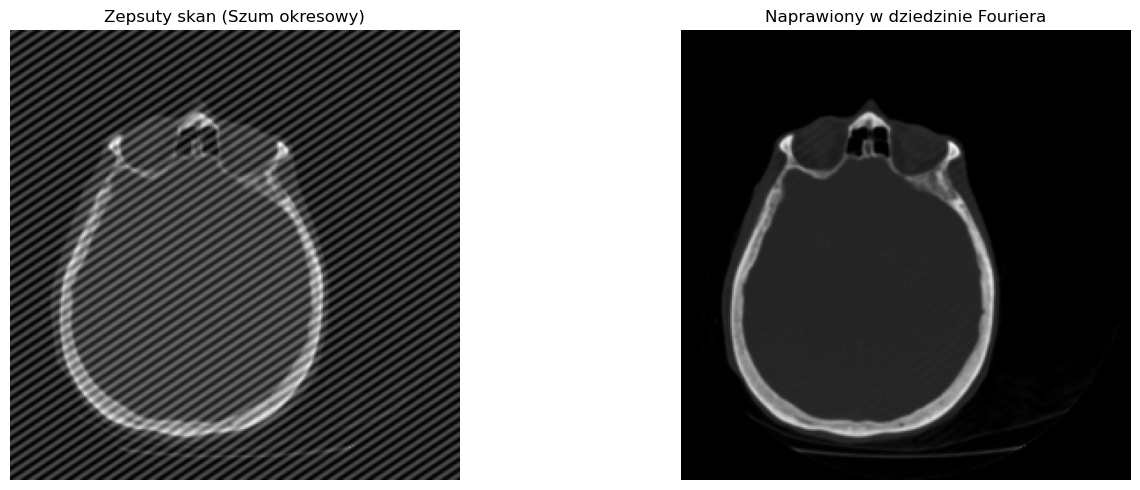

In [22]:
# Przygotowujemy obraz i symulujemy artefakt sprzętowy (regularną falę ukośną)
img_brain = data.brain()[1, :, :].astype(float)
img_brain = (img_brain - img_brain.min()) / (img_brain.max() - img_brain.min())
rows, cols = img_brain.shape
Y, X = np.ogrid[:rows, :cols]
freq_y, freq_x = 45, 30
noise = 0.2 * np.sin(2 * np.pi * (freq_y * Y / rows + freq_x * X / cols))
noisy_brain = img_brain + noise

# Przenosimy do Fouriera
f_transform = fftshift(fft2(noisy_brain))
f_clean = f_transform.copy()
center_row, center_col = rows // 2, cols // 2

# Wycinamy z widma częstotliwości odpowiadające szumowi
r = 5
f_clean[center_row - freq_y - r : center_row - freq_y + r, center_col - freq_x - r : center_col - freq_x + r] = 0
f_clean[center_row + freq_y - r : center_row + freq_y + r, center_col + freq_x - r : center_col + freq_x + r] = 0

# Powrót do obrazu
cleaned_brain = np.abs(ifft2(ifftshift(f_clean)))
show_images([noisy_brain, cleaned_brain], ["Zepsuty skan (Szum okresowy)", "Naprawiony w dziedzinie Fouriera"])

### 3. "Chirurgiczna" precyzja częstotliwościowa

Filtry przestrzenne (jak macierz rozmycia Gaussa) to zawsze kompromis matematyczny - wycinają częstotliwości w sposób łagodny (wykres dzwonowy). 
Operując w Fouriera możemy stworzyć **Idealny Filtr Dolnoprzepustowy**. 

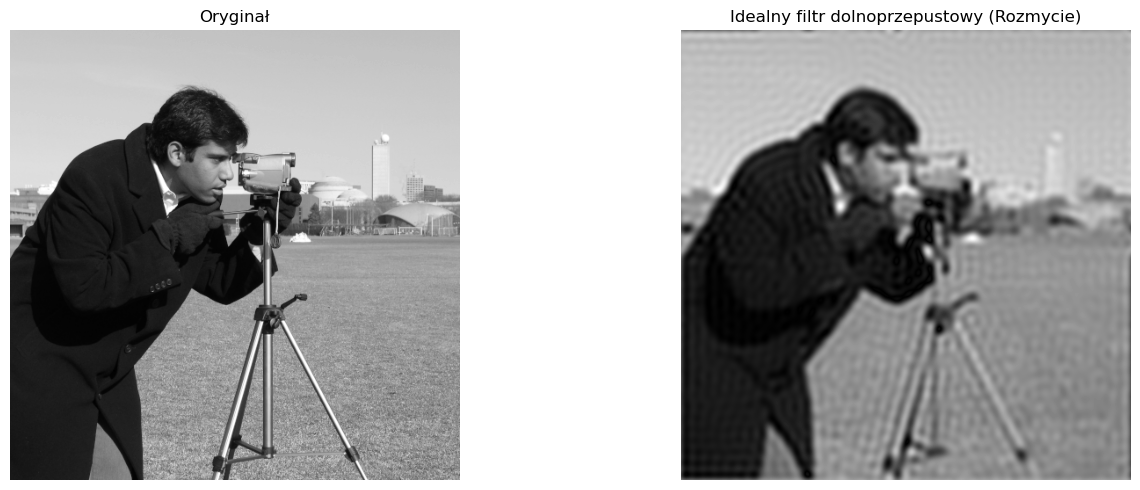

In [25]:
img_cam = data.camera() / 255.0
rows, cols = img_cam.shape
f_transform_cam = fftshift(fft2(img_cam))

# Idealne odcięcie w kształcie koła (rysowanie ostrej maski na widmie)
Y, X = np.ogrid[:rows, :cols]
center_row, center_col = rows // 2, cols // 2
dist = np.sqrt((X - center_col)**2 + (Y - center_row)**2)

# Zostawiamy idealnie tylko promień <= 40, a reszta staje się idealnym zerem
mask_ideal = dist <= 40
f_ideal = f_transform_cam * mask_ideal
img_ideal = np.abs(ifft2(ifftshift(f_ideal)))

show_images([img_cam, img_ideal], ["Oryginał", "Idealny filtr dolnoprzepustowy (Rozmycie)"])

### 4. Analiza kierunkowa i dekonwolucja (Filtrowanie Wienera)

Rozmycie spowodowane poruszeniem aparatu w czasie robienia zdjęcia (motion blur) nie usuwa informacji z obrazu na zawsze – ono ją tylko rozprasza w konkretnym kierunku. 

W dziedzinie przestrzennej jest to nie do uratowania. Ale w dziedzinie częstotliwości możemy ten proces "odwrócić" za pomocą tak zwanej dekonwolucji. Algorytm "dzieli" zamazany obraz przez zdefiniowaną funkcję rozmycia (PSF) i odzyskuje ostrość.

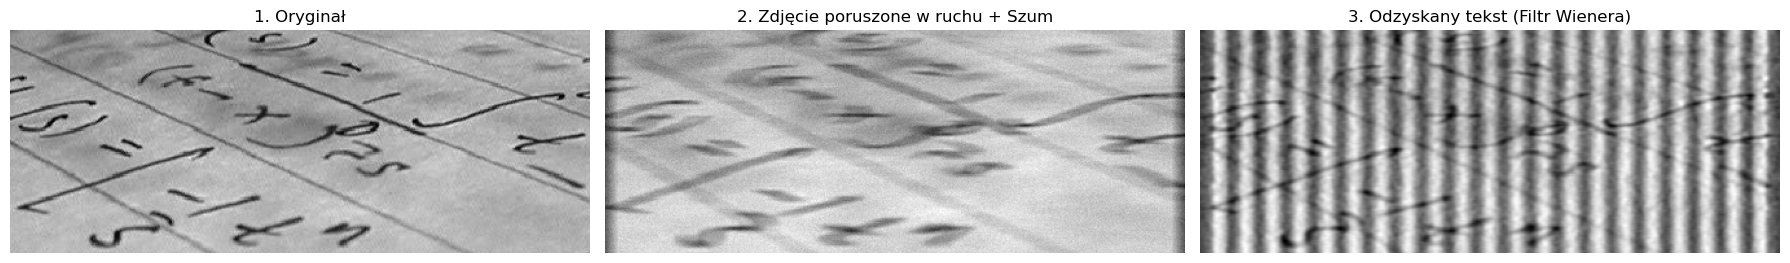

In [30]:
# Wczytanie obrazu testowego (tekst)
img_text = data.text() / 255.0

# Tworzymy PSF (Point Spread Function) symulujący aparat jadący w lewo/prawo (motion blur)
psf = np.zeros((21, 21))
psf[10, :] = 1.0 / 21.0  # 21 pikseli rozmycia w poziomie!

# Symulujemy zepsute, poruszone zdjęcie (splot z filtrem PSF)
blurred_text = fftconvolve(img_text, psf, mode='same')
# Dodajemy trochę szumu z matrycy (dla realizmu)
blurred_text += 0.015 * np.random.randn(*blurred_text.shape)

# Używamy Filtru Wienera (który działa w dziedzinie Fouriera),
# aby odwrócić matematycznie proces rozmycia (dekonwolucja)
deconvolved_text = restoration.wiener(blurred_text, psf, balance=0.01)

show_images([img_text, blurred_text, deconvolved_text], 
            ["1. Oryginał", "2. Zdjęcie poruszone w ruchu + Szum", "3. Odzyskany tekst (Filtr Wienera)"], figsize=(18, 6))